# Công bố tài chính · nguồn, thời điểm và giá trị bổ sung

Nguồn dữ liệu là hai tệp `financials.csv` trong `train_files` và `supplemental_files`. Đặc tả nằm trong `data_specifications/stock_fin_spec.csv`. Notebook XGBRanker gợi ý xem dữ liệu tài chính như một nhóm đầu vào riêng. Các tỷ số ở đây được tính lại trực tiếp từ dữ liệu JPX. [Nguồn JPX](https://www.kaggle.com/competitions/jpx-tokyo-stock-exchange-prediction/data) · [Notebook XGBRanker](../references/jpx-all-data-xgbranker.ipynb)

[Quyết định tiền xử lý](../../reports/jpx_release.md#dữ-liệu-và-quyết-định-tiền-xử-lý)

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file()
            and (p / "src/__init__.py").is_file())
results = root / "artifacts"
if not (results / "development_summary.csv").is_file():
    raise FileNotFoundError("Tạo các bảng kết quả theo reports/reproduce.md trước khi chạy notebook.")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
blue, green, red, gray = "#285A82", "#24796C", "#A63D40", "#687783"

import sys

sys.path.insert(0, str(root))
from src.preprocessing import KEY, eligible_bars
from src.release_data import RATIOS, financial_features, legacy_financial_features, prepare_disclosures
from src.release_experiment import CUTOFF, FINANCE

data = pd.read_pickle(results / "prices.pkl")
calendar = pd.DatetimeIndex(data.loc[data["Date"].lt(CUTOFF), "Date"].unique()).sort_values()
prices = data.loc[data["Date"].lt(CUTOFF), [*KEY, "Open", "High", "Low", "Close", "Volume"]]
del data
raw = pd.read_pickle(results / "financial.pkl")
published = pd.to_datetime(raw["DisclosedDate"], errors="coerce")
raw = raw.loc[published.lt(CUTOFF) | published.isna()].reset_index(drop=True)
keys = prices.loc[eligible_bars(prices), KEY].reset_index(drop=True)
updates, quality = prepare_disclosures(raw, calendar, keys["SecuritiesCode"].dtype)


## Kiểm tra tài liệu gốc

`NetSales` và `OperatingProfit` là giá trị lũy kế từ đầu kỳ năm tài chính theo đặc tả. `Equity` và `TotalAssets` là số dư tại cuối kỳ. Kỳ kế toán và phạm vi hợp nhất được theo dõi cùng mã tài liệu để truy vết.

In [2]:
display(pd.Series(quality, name="Số tài liệu"))
by_type = raw.groupby("TypeOfDocument", dropna=False).agg(
    **{"Số tài liệu": ("DisclosureNumber", "size"),
       "Thiếu lợi nhuận hoạt động": ("OperatingProfit", lambda x: x.isna().mean()),
       "Thiếu vốn chủ sở hữu": ("Equity", lambda x: x.isna().mean())}
).sort_values("Số tài liệu", ascending=False)
display(by_type.head(12).round(3))


Input documents                  92992
Invalid identity or timestamp        2
Duplicate records                    0
Conflicting records                  0
Eligible corrections              2312
Correction events                 2553
Name: Số tài liệu, dtype: int64

,Số tài liệu,Thiếu lợi nhuận hoạt động,Thiếu vốn chủ sở hữu
TypeOfDocument,,,
ForecastRevision,17003,1.000,1.000
FYFinancialStatements_Consolidated_JP,14783,0.025,0.000
3QFinancialStatements_Consolidated_JP,14736,0.032,0.000
1QFinancialStatements_Consolidated_JP,14721,0.032,0.000
2QFinancialStatements_Consolidated_JP,14628,0.026,0.000
NumericalCorrection,2553,0.080,0.077
FYFinancialStatements_NonConsolidated_JP,2459,0.004,0.000
3QFinancialStatements_NonConsolidated_JP,2414,0.004,0.000
1QFinancialStatements_NonConsolidated_JP,2406,0.004,0.000


Bản tin dự báo có thể mang sự kiện đáng quan sát dù không cung cấp số liệu thực tế. Hai tỷ số được tính từ số liệu thực tế và chỉ đổi khi có báo cáo hợp lệ cho tỷ số tương ứng. Hiệu lực bắt đầu từ phiên đầu sau ngày công bố.

## Độ phủ và ví dụ trước, sau công bố

Đủ hai tỷ số mới         Đủ hai tỷ số cũ        
                 mean    size            mean    size
Date                                                 
2017           0.8753  462591          0.7894  462591
2018           0.9676  466648          0.8838  466648
2019           0.9684  467078          0.8946  467078
2020           0.9693  477675          0.8613  477675
2021           0.9707  456913          0.8702  456913

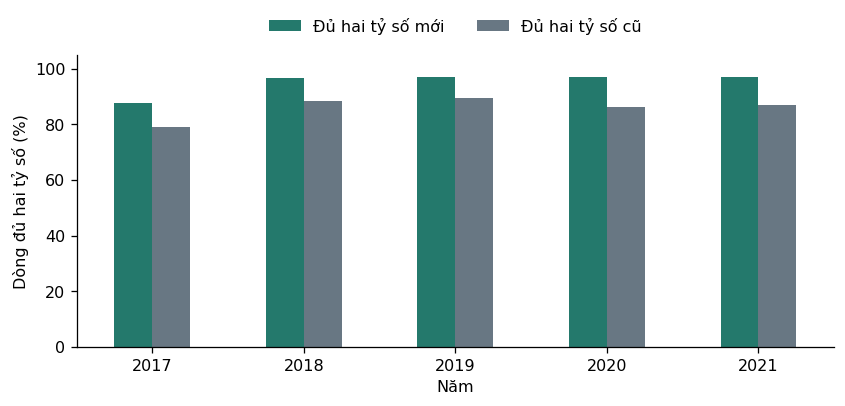

,Date,SecuritiesCode,operating_margin,equity_asset_ratio,forecast_revision_today,operating_margin_DisclosureNumber,operating_margin_effective,legacy_operating_margin,legacy_equity_asset_ratio
3675,2017-01-05,9793,NaN,NaN,0,NaN,NaT,NaN,NaN
5539,2017-01-06,9793,NaN,NaN,0,NaN,NaT,NaN,NaN
7399,2017-01-10,9793,0.1644,0.8594,1,20161226463370.0,2017-01-10,NaN,NaN
9260,2017-01-11,9793,0.1644,0.8594,0,20161226463370.0,2017-01-10,NaN,NaN
11118,2017-01-12,9793,0.1644,0.8594,0,20161226463370.0,2017-01-10,NaN,NaN


Dòng phục hồi được ít nhất một tỷ số theo phép đối chiếu này: 188,081.


In [3]:
fixed = financial_features(keys, raw, calendar)
old = legacy_financial_features(keys, raw, calendar)
year = keys["Date"].dt.year
coverage = pd.DataFrame({"Đủ hai tỷ số mới": fixed[list(RATIOS)].notna().all(axis=1),
                         "Đủ hai tỷ số cũ": old.iloc[:, :2].notna().all(axis=1)})
display(coverage.groupby(year).agg(["mean", "size"]).round(4))
ax = coverage.groupby(year).mean().mul(100).plot.bar(color=[green, gray], figsize=(8.5, 3.3), rot=0)
ax.set(xlabel="Năm", ylabel="Dòng đủ hai tỷ số (%)", ylim=(0, 105))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
plt.show()
rescued = old.iloc[:, :2].isna().all(axis=1) & fixed[list(RATIOS)].notna().any(axis=1)
joint = rescued & fixed["forecast_revision_today"].eq(1)
examples = keys.loc[joint]
if not examples.empty:
    day, stock = examples.iloc[0]
    end = calendar[calendar.get_loc(day) + 2] if calendar.get_loc(day) + 2 < len(calendar) else calendar[-1]
    sample = keys.loc[keys["SecuritiesCode"].eq(stock) & keys["Date"].between(day - pd.Timedelta(days=5), end)]
    trace = financial_features(sample, raw, calendar, include_source=True)
    display(sample.join(trace[[*RATIOS, "forecast_revision_today", "operating_margin_DisclosureNumber",
                               "operating_margin_effective"]]).join(old.iloc[:, :2]).round(4))
print(f"Dòng phục hồi được ít nhất một tỷ số theo phép đối chiếu này: {int(rescued.sum()):,}.")


Hai tỷ số có thể có tuổi và tài liệu nguồn khác nhau. Trong ví dụ, xem cột ngày hiệu lực và mã tài liệu để phân biệt ngày báo cáo mới với ngày tỷ số thực tế thay đổi. Tỷ lệ theo năm có mẫu số là các dòng giá hợp lệ ở cuối phiên. Tính trên toàn bộ phần phát triển, tỷ lệ có đủ hai tỷ số tăng từ 86,00% lên 95,04%.

## Đóng góp trên validation

In [4]:
names = ["LightGBM OHLCV", "LightGBM ratios", "LightGBM report availability",
         "LightGBM report events", FINANCE, "LightGBM legacy finance", "LightGBM finance median"]
daily = pd.read_csv(results / "development_daily.csv")
spread = daily.pivot(index="Date", columns="Model", values="Spread")[names].dropna()
report = pd.DataFrame({"Sharpe": spread.mean().div(spread.std()), "Spread (bps/phiên)": spread.mean() * 10_000,
                       "Phiên chung": len(spread)})
display(report.reindex(names).round(4))


,Sharpe,Spread (bps/phiên),Phiên chung
Model,,,
LightGBM OHLCV,0.0775,3.7752,700
LightGBM ratios,0.1058,5.8484,700
LightGBM report availability,0.0987,4.2248,700
LightGBM report events,0.0904,4.4413,700
LightGBM finance,0.1252,6.0520,700
LightGBM legacy finance,0.1151,5.2884,700
LightGBM finance median,0.1305,6.4335,700


Các hàng cùng dùng LightGBM và ngày đánh giá chung. Nhóm tuổi và cờ thiếu đo tín hiệu đến từ sự có mặt của dữ liệu. Nhóm tỷ số và nhóm sự kiện kiểm tra hai nguồn tín hiệu khác nhau. Hàng điền trung vị đo ảnh hưởng của tiền xử lý so với để mô hình xử lý ô thiếu.